# 03 — Regresión del monto del crédito (`hoehe`)

**Proyecto:** Análisis de riesgo crediticio · South German Credit (UCI, id 573)  
**Alumno:** Alexander Domínguez Zárate · UTTT · Unidad III

**Objetivo:** predecir el **monto solicitado** (`hoehe`, en DM de 1994) a partir del perfil del
cliente en el momento de la solicitud. La regresión responde una pregunta de política comercial:
*¿cuánto pediría un cliente con este perfil?* — útil para presupuestar exposición y detectar
solicitudes atípicas.

**Fuente de verdad:** `src/models/entrenar_regresion.py`. Este notebook **reutiliza sus funciones**
(pipeline, comparación por CV, evaluación y diagnóstico) sin duplicar lógica, y documenta la
interpretación de cada paso.


In [1]:
import os
import sys

import pandas as pd
from IPython.display import Image, display

# trabajar desde la raiz del repo para que las rutas del script sean validas
os.chdir('..')
sys.path.insert(0, os.path.abspath('src/models'))

import entrenar_regresion as reg

print('dataset:', reg.CSV_PATH)
print('features:', len(reg.FEATURES), '| target:', reg.TARGET)


dataset: data\processed\south_german_credit_processed.csv
features: 19 | target: hoehe


## 1) Datos y definición del problema

Variables de entrada: 2 numéricas (`laufzeit` plazo, `alter` edad) + 17 categóricas `*_cat`.

**Exclusión por fuga de información (leakage).** Tres columnas del dataset procesado NO se usan:

- `kredit` / `kredit_cat`: el resultado del contrato se conoce *después* de otorgar el crédito;
   incluirlo haría el modelo inútil en producción.
- `cuota_aprox_mensual`: es `hoehe / laufzeit`, una función determinista del objetivo (prediría
   el monto casi perfectamente sin aprender nada del cliente).


In [2]:
df = reg.cargar_dataset()
print('shape:', df.shape)
df[reg.FEATURES + [reg.TARGET]].head()


shape: (1000, 40)


,laufzeit,alter,laufkont_cat,moral_cat,verw_cat,sparkont_cat,beszeit_cat,rate_cat,famges_cat,buerge_cat,wohnzeit_cat,verm_cat,weitkred_cat,wohn_cat,bishkred_cat,beruf_cat,pers_cat,telef_cat,gastarb_cat,hoehe
0,18,21,no_checking,all_bank_paid,car_used,unknown,lt1,lt20,female_nonsingle_or_male_single,none,ge7,car_other,none,free,1,skilled_official,0_to_2,no,no,1049
1,9,36,no_checking,all_bank_paid,others,unknown,1_to_4,25_to_35,male_married_widowed,none,1_to_4,unknown,none,free,2_3,skilled_official,ge3,no,no,2799
2,12,23,lt0,no_credits_or_paid,retraining,lt100,4_to_7,25_to_35,female_nonsingle_or_male_single,none,ge7,unknown,none,free,1,unskilled_resident,0_to_2,no,no,841
3,12,39,no_checking,all_bank_paid,others,unknown,1_to_4,20_to_25,male_married_widowed,none,1_to_4,unknown,none,free,2_3,unskilled_resident,ge3,no,yes,2122
4,12,38,no_checking,all_bank_paid,others,unknown,1_to_4,lt20,male_married_widowed,none,ge7,car_other,bank,rent,2_3,unskilled_resident,0_to_2,no,yes,2171


In [3]:
X, y = reg.X_y(df)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print('train:', X_train.shape, '| test:', X_test.shape)
print('monto: media %.0f DM | mediana %.0f DM' % (y.mean(), y.median()))


train: (800, 19) | test: (200, 19)
monto: media 3271 DM | mediana 2320 DM


**Interpretación del split.** 800 créditos para entrenar y 200 para evaluar (80/20). El monto
promedio es ≈ 3271 DM (mediana ≈ 2333 DM): esos números serán la referencia para juzgar si un
error de predicción es grande o pequeño. No estratificamos porque el objetivo es continuo.


## 2) Comparación de candidatos con validación cruzada 5-fold

Cuatro candidatos sobre el mismo pipeline (one-hot para categóricas + estandarización de numéricas):
un baseline trivial (mediana), OLS, Ridge α=1 y Ridge con α seleccionado internamente (`RidgeCV`).
La regularización L2 de Ridge penaliza coeficientes grandes — relevante aquí por las muchas
categóricas one-hot.


In [4]:
tabla = reg.comparar_modelos(X_train, y_train)
tabla.round(2)


,modelo,rmse_cv,rmse_std,mae_cv,r2_cv
0,ridge_cv,1887.10,216.96,1317.57,0.55
1,ridge_a1,1902.48,213.75,1356.32,0.54
2,lineal_ols,1908.98,214.48,1361.66,0.54
3,baseline_mediana,2974.67,224.53,1916.84,-0.12


**Interpretación de la comparación.** El baseline de la mediana tiene R² negativo (−0.12): predecir
siempre 2333 DM es *peor* que la media, señal de que las features sí contienen señal. Los tres
modelos lineales empatan casi exactamente (RMSE ≈ 1890–1910, R² ≈ 0.54): la regularización no cambia
el techo predictivo, lo que sugiere que el límite es la **información disponible**, no la complejidad
del modelo. `ridge_cv` gana por margen mínimo y es el que se evalúa en test.


## 3) Evaluación en test (datos nunca vistos)


In [5]:
from sklearn.linear_model import RidgeCV
import numpy as np

pipe = reg.construir_pipeline(RidgeCV(alphas=np.logspace(-3, 3, 13)))
metricas, pred = reg.evaluar_test(pipe, X_train, y_train, X_test, y_test)
{k: round(v, 3) for k, v in metricas.items()}


{'mae_test': 1138.554, 'rmse_test': 1798.142, 'r2_test': 0.596}

**Interpretación de las métricas de test.** R² = **0.596**: el modelo explica ≈ 60 % de la varianza
del monto. RMSE = **1798 DM**: un error típico de ±1800 DM sobre un monto medio de 3271 DM —
útil para presupuestos agregados, no para aprobar un contrato individual. MAE = **1139 DM**
(menor que RMSE ⇒ hay errores grandes en pocos casos, típicamente créditos muy largos/cortos).
Coherente con el Data Mart (Q5): el monto se relaciona con el perfil, pero con mucho ruido idiosincrático.


## 4) Coeficientes estandarizados — qué mueve el monto

Las numéricas están estandarizadas y las categóricas van one-hot, así que los coeficientes son
comparables: "efecto sobre el monto (DM) por cada desviación estándar" o "de esa categoría vs. base".


In [6]:
top = reg.coeficientes_estandarizados(pipe).head(12)
top.round(1)


,feature,coef
0,num__laufzeit,1488.3
1,cat__rate_cat_lt20,-1043.0
2,cat__rate_cat_ge35,925.4
3,cat__beruf_cat_high_qual_selfemp,725.2
4,cat__verw_cat_business,614.8
5,cat__verw_cat_car_new,538.3
6,cat__moral_cat_delay,396.8
7,cat__sparkont_cat_ge1000,350.1
8,cat__famges_cat_female_single,-337.4
9,cat__laufkont_cat_lt0,331.1


**Interpretación de los coeficientes.**

- `laufzeit` (+1488 DM por σ): el plazo es el gran determinista del monto — a más plazo, más dinero
   solicitado. Es también la variable con cuota asociada (ver notebook 02).
- `rate_cat_lt20` (−1043) y `rate_cat_ge35` (+925): la tasa de cuota «baja» (<20 % del ingreso)
   aparece en créditos grandes de plazo largo; la cuota pesada (≥35 %) en créditos pequeños de plazo
   corto. El modelo redescubre la relación monto = cuota × plazo sin ver `rate` como fórmula.
- `verw_car_new` (+538) y `verw_business` (+615): auto nuevo y negocio piden más (Q2 del Data Mart:
   business promedia 8209 DM).
- `moral_delay` (+397): los clientes con historial de atraso piden montos mayores — el segmento
   riesgoso también es el de mayor exposición.

**Caveat documentado:** `hoehe` en este dataset es una transformación monótona no documentada del
monto original (no son DM exactos), por lo que las unidades absolutas son orientativas.


## 5) Diagnóstico gráfico


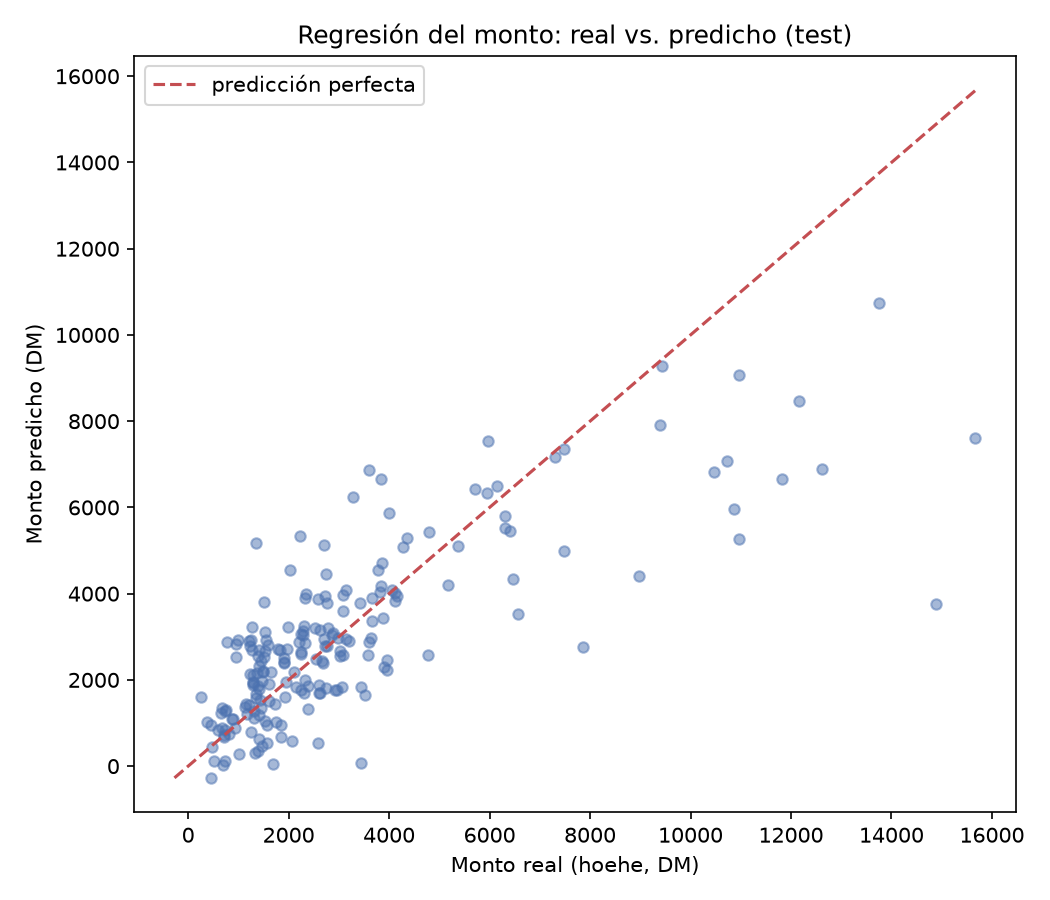

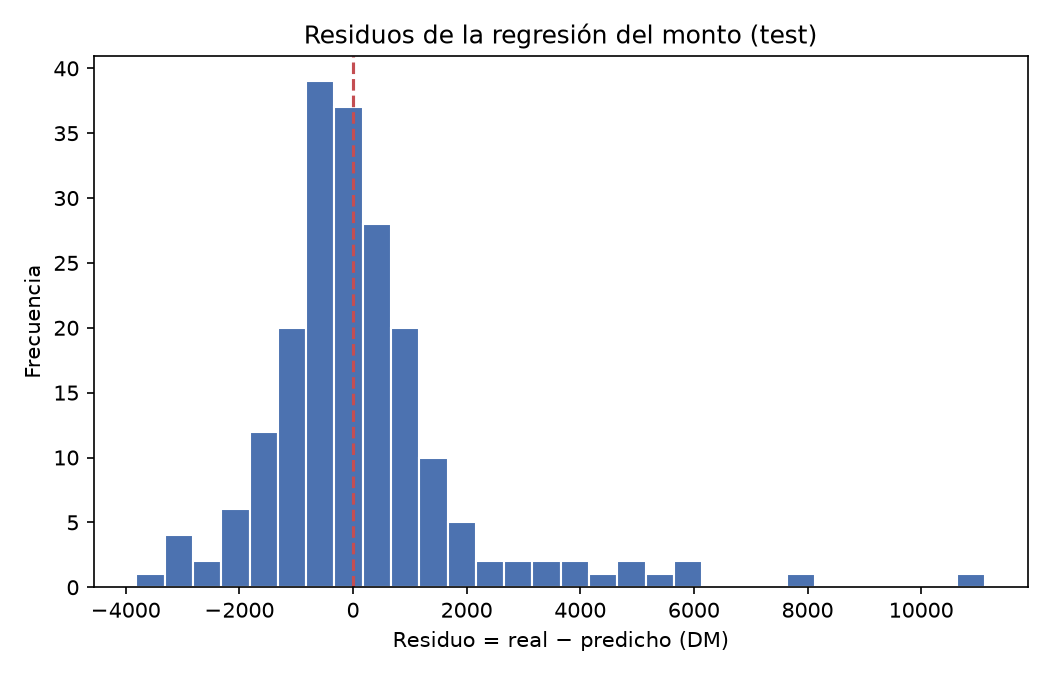

In [7]:
rutas = reg.graficar_diagnostico(y_test.reset_index(drop=True), pd.Series(pred))
display(Image(filename=rutas[0]))
display(Image(filename=rutas[1]))


**Interpretación del diagnóstico.** En *real vs. predicho* la nube sigue la diagonal en la zona
central (2000–6000 DM) pero el modelo **satura en los extremos**: predice máximos ≈ 8000 DM cuando
hay créditos de 18000+, porque ninguna feature explica esos montos extremos. El histograma de
residuos es aproximadamente simétrico con cola derecha: subestimar créditos grandes es el error
sistemático principal. Consecuencia práctica: usar el modelo por rango, no punto a punto.


## 6) Reproducción completa y artefactos

La ejecución canónica de todo el pipeline (comparación + test + figuras + `modelos/regresion/*.pkl`
+ `metricas.json`) es la del script. Se corre aquí para verificar la reproducibilidad end-to-end:


In [8]:
salida = reg.main()
print('alpha seleccionado:', salida['alpha_seleccionado'])


=== Comparación por CV 5-fold (train) ===


          modelo  rmse_cv  rmse_std  mae_cv  r2_cv
        ridge_cv  1887.10    216.96 1317.57   0.55
        ridge_a1  1902.48    213.75 1356.32   0.54
      lineal_ols  1908.98    214.48 1361.66   0.54
baseline_mediana  2974.67    224.53 1916.84  -0.12

mejor por CV RMSE: ridge_cv


=== Métricas en test ===
{'mae_test': 1138.554, 'rmse_test': 1798.142, 'r2_test': 0.596}

=== Top 10 coeficientes (estandarizados) ===
                         feature    coef
                   num__laufzeit  1488.3
              cat__rate_cat_lt20 -1043.0
              cat__rate_cat_ge35   925.4
cat__beruf_cat_high_qual_selfemp   725.2
          cat__verw_cat_business   614.8
           cat__verw_cat_car_new   538.3
            cat__moral_cat_delay   396.8
        cat__sparkont_cat_ge1000   350.1
   cat__famges_cat_female_single  -337.4
           cat__laufkont_cat_lt0   331.1



figuras: ['docs\\modelos\\figuras\\reg_pred_vs_real.png', 'docs\\modelos\\figuras\\reg_residuos.png']
metricas guardadas: modelos\regresion\metricas.json
alpha seleccionado: 31.622776601683793


## 7) Conclusión de la regresión

Con un modelo lineal regularizado y variables conocidas al momento de la solicitud se explica
**≈ 60 %** de la varianza del monto (R² test 0.596, RMSE 1798 DM). El plazo y la estructura de
cuota dominan la predicción; las categorías de propósito e historial aportan el resto.
Los créditos de exposición extrema (>8000 DM) quedan subestimados — se recomienda tratarlos con
reglas aparte (ver Data Mart Q4/Q5).

**Siguiente:** clasificación del riesgo crediticio (`kredit`) en `04_clasificacion.ipynb`.
